In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../data/raw"
read = lambda name: pd.read_csv(f"{DATA}/{name}", dtype={"student_id": str})

CLEAN = "../data/clean"
read_clean = lambda name: pd.read_csv(f"{CLEAN}/{name}", dtype={"student_id": str})

grades = read_clean("term_grades_clean.csv.gz")
courses = read("courses.csv")  # not in data/clean, so read from the raw data
students = read_clean("students_clean.csv")
refs = read_clean("tutoring_referrals_clean.csv")

keys = ["student_id", "subject_area"]

# Keep the three tutored subjects
df = grades.merge(courses[["course_code", "subject_area"]], on="course_code")
df = df[df["subject_area"].isin(["Mathematics", "English Language Arts", "Science"])]

# failed: F in term 1, below 60 in terms 2 and 3
df["failed"] = df["term_grade"].eq("F") | pd.to_numeric(df["term_grade"], errors="coerce").lt(60)

# referred and referral_term
dates = pd.to_datetime(refs["referral_date"])
refs["referral_term"] = 1 + (dates > "2025-10-31").astype(int) + (dates > "2026-02-13").astype(int)
df = df.merge(refs[keys + ["referral_term"]], on=keys, how="left")
df["referred"] = df["referral_term"].notna()

# gpa_band
df = df.merge(students[["student_id", "prior_year_gpa"]], on="student_id")
df["gpa_band"] = pd.cut(df["prior_year_gpa"], [0, 1, 2, 3, 4], include_lowest=True,
                        labels=["0-1", "1-2", "2-3", "3-4"])

print("Rows:", len(df))
print(df.groupby("referred")["failed"].mean() * 100)

Rows: 360000
referred
False     9.607326
True     23.910080
Name: failed, dtype: float64


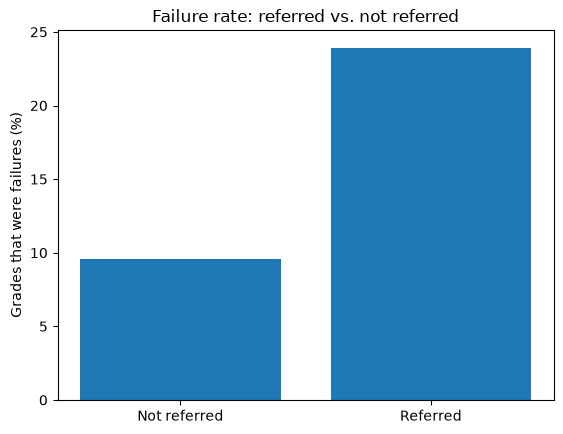

In [2]:
rates = df.groupby("referred")["failed"].mean() * 100

plt.bar(["Not referred", "Referred"], rates)
plt.ylabel("Grades that were failures (%)")
plt.title("Failure rate: referred vs. not referred")
plt.show()

          Not referred  Referred
gpa_band                        
0-1               93.7      86.4
1-2               51.2      43.0
2-3               11.2      10.1
3-4                0.6       0.5
Blank             13.0       9.3


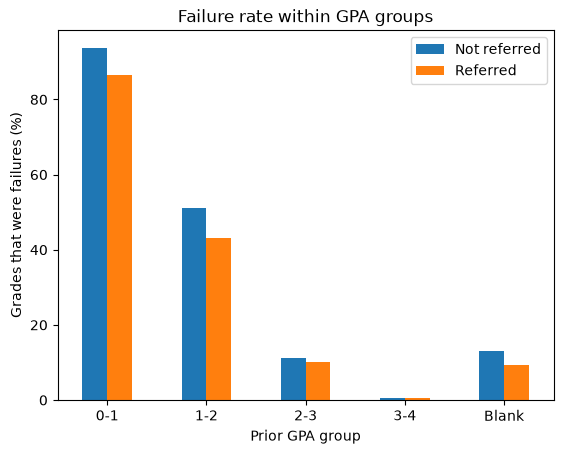

In [3]:
# Failure rate within each GPA group, keeping blank GPAs as their own group
bands = df["gpa_band"].cat.add_categories("Blank").fillna("Blank")
table = df.groupby([bands, "referred"], observed=True)["failed"].mean().unstack() * 100
table.columns = ["Not referred", "Referred"]

print(table.round(1))

table.plot(kind="bar", rot=0)
plt.xlabel("Prior GPA group")
plt.ylabel("Grades that were failures (%)")
plt.title("Failure rate within GPA groups")
plt.show()

      Referred in term 1  Referred in term 2  Referred in term 3  Not referred
term                                                                          
1                   23.8                34.2                34.7           9.5
2                   23.7                25.9                36.9          10.5
3                   19.7                19.0                20.4           8.9


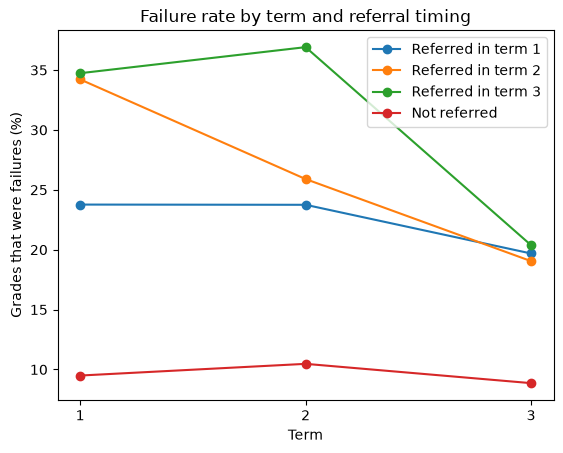

In [4]:
# Failure rate by term, grouped by when the student was referred
trend = df[df["referred"]].groupby(["term", "referral_term"])["failed"].mean().unstack() * 100
trend.columns = ["Referred in term 1", "Referred in term 2", "Referred in term 3"]
trend["Not referred"] = df[~df["referred"]].groupby("term")["failed"].mean() * 100

print(trend.round(1))

trend.plot(marker="o")
plt.xticks([1, 2, 3])
plt.xlabel("Term")
plt.ylabel("Grades that were failures (%)")
plt.title("Failure rate by term and referral timing")
plt.show()

In [ ]:
# Clean the session log and report what changed
sessions = read_clean("tutoring_sessions_clean.csv.gz")
print("Rows before cleaning:", len(sessions))
sessions["subject_area"] = sessions["subject_area"].str.strip()
print("Exact copy rows:", sessions.duplicated().sum())
sessions = sessions.drop_duplicates()
print("Rows after cleaning:", len(sessions))

# attendance_rate for each student in each subject
sessions["present"] = sessions["attendance"].eq("Present")
att = sessions.groupby(keys)["present"].agg(scheduled="size", attended="sum").reset_index()
att["attendance_rate"] = att["attended"] / att["scheduled"]
print("Student-subject pairs:", len(att))
print("Mean attendance:", round(att["attendance_rate"].mean() * 100, 1))

att = att.merge(students[["student_id", "bus_rider"]], on="student_id")
term3 = df[df["term"] == 3][keys + ["failed"]]
att = att.merge(term3, on=keys)
att["attendance_band"] = pd.cut(att["attendance_rate"], [0, 0.25, 0.5, 0.75, 1], include_lowest=True,
                                labels=["0-25%", "25-50%", "50-75%", "75-100%"])

bus = att.groupby("bus_rider")["attendance_rate"].mean() * 100
fail = att.groupby("attendance_band", observed=True)["failed"].mean() * 100
print(bus.round(1))
print(fail.round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(att["attendance_rate"] * 100, bins=20)
axes[0].set_xlabel("Sessions attended (%)")
axes[0].set_ylabel("Student-subject pairs")
axes[0].set_title("Attendance rates")

axes[1].bar(["Non-riders", "Bus riders"], bus)
axes[1].set_ylabel("Mean attendance (%)")
axes[1].set_title("Attendance by bus rider status")

axes[2].bar(fail.index.astype(str), fail)
axes[2].set_xlabel("Sessions attended")
axes[2].set_ylabel("Term 3 grades that were failures (%)")
axes[2].set_title("Term 3 failure rate by attendance")

plt.tight_layout()
plt.show()

Rows before cleaning: 413370


In [ ]:
# Term 3 failure rate by attendance, within each GPA group (blank GPAs not shown)
bands = df[["student_id", "gpa_band"]].drop_duplicates()
check = att.merge(bands, on="student_id")

rates = check.groupby(["gpa_band", "attendance_band"], observed=True)["failed"].mean().unstack() * 100
sizes = check.groupby(["gpa_band", "attendance_band"], observed=True)["failed"].size().unstack()

print(rates.round(1))
print(sizes)

rates.plot(kind="bar", rot=0)
plt.xlabel("Prior GPA group")
plt.ylabel("Term 3 grades that were failures (%)")
plt.title("Term 3 failure rate by attendance, within GPA groups")
plt.legend(title="Sessions attended")
plt.show()

## What the exploration shows

1. Referred grades fail more often overall: 23.9% vs. 9.6%.
2. Within every prior GPA group, including blank GPAs, the referred rate is lower.
3. Students referred in terms 2 and 3 were already failing far more often than non-referred students before referral.
4. Referred students attended 56.8% of scheduled sessions on average. Bus riders attended 53.4%, and non-riders 62.1%.
5. Within the 0-1, 1-2 and 2-3 GPA groups, term 3 failure falls as attendance rises.

## Specific problem

The headline comparison treats referred students as one group and ignores where they started and whether they attended. The specific problem is: among referred students with similar starting points, is attending more sessions linked to lower failure, and does the lack of late buses limit attendance?

These are patterns, not proof. Attendance happens after referral, and students who attend more may differ in ways this data doesn't record.